# Survival Lab

We've looked at normal-linear regression and probit regression from a likelihood perspective, which yields two log-likelihoods:
$$
LL(\beta,\sigma) = - n \log( \sqrt{2\pi} ) - n \log(\sigma) - \frac{1}{2\sigma^2} \sum_{i=1}^n (y_i - x_i \beta)^2
$$
and
$$
LL(\beta) = \sum_{i=1}^N y_i \log(\Phi(x_i \cdot \beta/\sigma)) + (1-y_i) \log(1-\Phi(x_i \cdot \beta/\sigma)).
$$
This lab combines them by looking at **right-censored** survival data.

We are going to use the Metabric breast cancer dataset to predict how long someone survives after being treated for breast cancer. For the regressions that follow, include the following as numeric variables:

- 'Age at Diagnosis'
- 'Lymph nodes examined positive'
- 'Mutation Count'
- 'Tumor Size'

and the following as categorical variables (one-hot encode them):

- 'Chemotherapy'
- 'Hormone Therapy'
- 'Radio Therapy'
- 'Tumor Stage'

The outcome variable of interest is the log of `Overall Survival (Months)`, which we'll refer to as log-months.

1. Load the `./data/metabric.csv` data. Tabulate `Overall Survival Status` to see who is alive or dead at the time the study ends. Make a kernel density plot of `Overall Survival (Months)`, hued by `Overall Survival Status`, to see the difference between survival duration for those alive and those dead at the time the study ended. **Drop the observations for which `Tumor Stage` is zero.**
2. Use Scikit's `train_test_split` with a `test_size` of .2. There are two tempting -- but ultimately incorrect -- ways to handle the Survival Status issue:
    - Use the reported `Overall Survival (Months)` as the target variable
    - Drop everyone who is alive at the time the study ends
Run these flawed regressions and save the coefficients and test-set predictions. Explain clearly how the first option is an example of imputation and the second treats survival as missing data.
3. Derive the log-likelihood for a model where the normal density is used for log-months when the subject died during the study (and log-months is observed, as in linear-normal regression), and the survival probability based on the Normal distribution is used when the patient is alive when the study ends (and log-months is a latent variable, as in a binary probit).
4. We want to estimate the model in part 3. You can do this with the `lifelines` package's `LogNormalAFTFitter`, or use the code chunk below to extend StatsModels to estimate this kind of model.
5. Compare the coefficients and test-set predictions (be careful to keep an eye on the censoring) for the censored MLE and the two linear models. Can you identify any groups who receive systematically biased predictions from the imputation and missing data approaches? 

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
from statsmodels.base.model import GenericLikelihoodModel
from scipy.stats import norm
from lifelines import LogNormalAFTFitter

# Part 1

In [17]:
metabric = pd.read_csv('data/metabric.csv')
metabric = metabric[metabric["Tumor Stage"] != 0]
metabric

,Age at Diagnosis,Type of Breast Surgery,Cancer Type,Chemotherapy,Hormone Therapy,Lymph nodes examined positive,Mutation Count,Nottingham prognostic index,Overall Survival (Months),Overall Survival Status,Radio Therapy,TMB (nonsynonymous),Tumor Size,Tumor Stage
0,43.19,BREAST CONSERVING,Breast Cancer,NO,YES,0.0,2.0,4.020,84.633333,0:LIVING,YES,2.615035,10.0,1.0
1,48.87,MASTECTOMY,Breast Cancer,YES,YES,1.0,2.0,4.030,163.700000,1:DECEASED,NO,2.615035,15.0,2.0
2,47.68,MASTECTOMY,Breast Cancer,YES,YES,3.0,1.0,4.050,164.933333,0:LIVING,YES,1.307518,25.0,2.0
3,76.97,MASTECTOMY,Breast Cancer,YES,YES,8.0,2.0,6.080,41.366667,1:DECEASED,YES,2.615035,40.0,2.0
4,78.77,MASTECTOMY,Breast Cancer,NO,YES,0.0,4.0,4.062,7.800000,1:DECEASED,YES,5.230071,31.0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1338,70.65,BREAST CONSERVING,Breast Cancer,NO,NO,0.0,9.0,2.040,201.166667,0:LIVING,YES,11.767659,20.0,1.0
1339,75.62,MASTECTOMY,Breast Cancer,NO,NO,0.0,4.0,4.040,105.200000,1:DECEASED,NO,5.230071,20.0,1.0
1340,52.84,BREAST CONSERVING,Breast Cancer,YES,NO,6.0,5.0,5.040,200.333333,0:LIVING,YES,6.537589,20.0,2.0
1341,48.59,MASTECTOMY,Breast Cancer,YES,NO,1.0,6.0,5.060,14.700000,1:DECEASED,YES,7.845106,30.0,2.0


In [18]:
metabric["Overall Survival Status"].value_counts()

Overall Survival Status
1:DECEASED    768
0:LIVING      573
Name: count, dtype: int64

<Axes: xlabel='Overall Survival (Months)', ylabel='Density'>

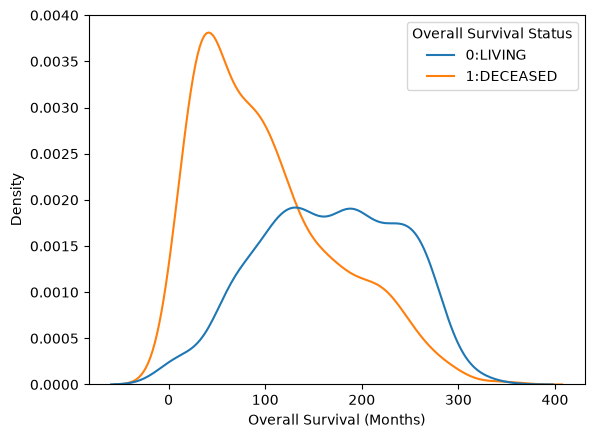

In [19]:
sns.kdeplot(data=metabric, x="Overall Survival (Months)", hue="Overall Survival Status")

**The majority of patients who passed did so after around 50-60 months. Unlike the plot of deceased patients, the plot of living patients has no obvious single peak and instead has 3 smaller peaks at 100-110, 190-200, and 250-260. At around 130-140 months, the density of people who lived exceed the density of people who passed.**

# Part 2

In [20]:
metabric.columns

Index(['Age at Diagnosis', 'Type of Breast Surgery', 'Cancer Type',
       'Chemotherapy', 'Hormone Therapy', 'Lymph nodes examined positive',
       'Mutation Count', 'Nottingham prognostic index',
       'Overall Survival (Months)', 'Overall Survival Status', 'Radio Therapy',
       'TMB (nonsynonymous)', 'Tumor Size', 'Tumor Stage'],
      dtype='object')

In [21]:
metabric = metabric[['Age at Diagnosis', 'Lymph nodes examined positive', 'Mutation Count', 'Tumor Size', 'Hormone Therapy', 
                     'Chemotherapy', 'Radio Therapy', 'Tumor Stage', 'Overall Survival (Months)', 'Overall Survival Status']]

In [22]:
metabric['Overall Survival Status'] = metabric['Overall Survival Status'].str[0].astype(int) # 1 - deceased, 0 - living
metabric['Overall Survival Status'].value_counts()

C:\Users\derek\AppData\Local\Temp\ipykernel_11256\1715235932.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  metabric['Overall Survival Status'] = metabric['Overall Survival Status'].str[0].astype(int) # 1 - deceased, 0 - living


Overall Survival Status
1    768
0    573
Name: count, dtype: int64

In [23]:
metabric = metabric.rename(columns={'Overall Survival Status': 'event'})
metabric

,Age at Diagnosis,Lymph nodes examined positive,Mutation Count,Tumor Size,Hormone Therapy,Chemotherapy,Radio Therapy,Tumor Stage,Overall Survival (Months),event
0,43.19,0.0,2.0,10.0,YES,NO,YES,1.0,84.633333,0
1,48.87,1.0,2.0,15.0,YES,YES,NO,2.0,163.700000,1
2,47.68,3.0,1.0,25.0,YES,YES,YES,2.0,164.933333,0
3,76.97,8.0,2.0,40.0,YES,YES,YES,2.0,41.366667,1
4,78.77,0.0,4.0,31.0,YES,NO,YES,4.0,7.800000,1
...,...,...,...,...,...,...,...,...,...,...
1338,70.65,0.0,9.0,20.0,NO,NO,YES,1.0,201.166667,0
1339,75.62,0.0,4.0,20.0,NO,NO,NO,1.0,105.200000,1
1340,52.84,6.0,5.0,20.0,NO,YES,YES,2.0,200.333333,0
1341,48.59,1.0,6.0,30.0,NO,YES,YES,2.0,14.700000,1


In [24]:
X = metabric.drop(columns=['Overall Survival (Months)', 'event'])
y = metabric['Overall Survival (Months)']

In [25]:
X = pd.get_dummies(X, columns=['Hormone Therapy', 'Chemotherapy', 'Radio Therapy', 'Tumor Stage'], drop_first=True, dtype=float)
X = sm.add_constant(X)
y = np.log(y)
y

0       4.438328
1       5.098035
2       5.105541
3       3.722475
4       2.054124
          ...   
1338    5.304134
1339    4.655863
1340    5.299983
1341    2.687847
1342    5.640132
Name: Overall Survival (Months), Length: 1341, dtype: float64

In [26]:
X

,const,Age at Diagnosis,Lymph nodes examined positive,Mutation Count,Tumor Size,Hormone Therapy_YES,Chemotherapy_YES,Radio Therapy_YES,Tumor Stage_2.0,Tumor Stage_3.0,Tumor Stage_4.0
0,1.0,43.19,0.0,2.0,10.0,1.0,0.0,1.0,0.0,0.0,0.0
1,1.0,48.87,1.0,2.0,15.0,1.0,1.0,0.0,1.0,0.0,0.0
2,1.0,47.68,3.0,1.0,25.0,1.0,1.0,1.0,1.0,0.0,0.0
3,1.0,76.97,8.0,2.0,40.0,1.0,1.0,1.0,1.0,0.0,0.0
4,1.0,78.77,0.0,4.0,31.0,1.0,0.0,1.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...
1338,1.0,70.65,0.0,9.0,20.0,0.0,0.0,1.0,0.0,0.0,0.0
1339,1.0,75.62,0.0,4.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0
1340,1.0,52.84,6.0,5.0,20.0,0.0,1.0,1.0,1.0,0.0,0.0
1341,1.0,48.59,1.0,6.0,30.0,0.0,1.0,1.0,1.0,0.0,0.0


In [27]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [28]:
train = metabric.loc[X_train.index]
test = metabric.loc[X_test.index]
train

,Age at Diagnosis,Lymph nodes examined positive,Mutation Count,Tumor Size,Hormone Therapy,Chemotherapy,Radio Therapy,Tumor Stage,Overall Survival (Months),event
812,59.23,0.0,7.0,18.0,NO,NO,YES,1.0,263.033333,0
1290,64.93,0.0,12.0,26.0,YES,NO,NO,2.0,17.833333,0
593,45.00,0.0,6.0,28.0,YES,NO,NO,1.0,41.533333,1
975,46.95,0.0,5.0,25.0,NO,NO,YES,2.0,189.866667,0
891,83.27,1.0,6.0,10.0,YES,NO,YES,2.0,176.266667,1
...,...,...,...,...,...,...,...,...,...,...
1097,69.20,0.0,5.0,40.0,YES,NO,NO,2.0,216.866667,1
1132,73.01,0.0,8.0,27.0,YES,NO,YES,2.0,57.666667,1
1296,41.53,4.0,3.0,20.0,NO,YES,YES,2.0,180.633333,0
862,57.95,0.0,4.0,50.0,YES,NO,YES,2.0,245.500000,0


In [29]:
ols_all = sm.OLS(y_train, X_train).fit()
ols_dead = sm.OLS(y_train[train["event"] == 1], X_train[train["event"] == 1]).fit()

**Using the reported Overall Survival in Months is an example of imputation because we are assuming the minimum survival time to be the actual; we are substituting unknown values with the minimum known value. Dropping only people who are alive at the end of the study means that missing values are not random, which distorts results towards early deaths.**

# Part 3

<img src='IMG_5978.jpeg'>

# Part 4

In [30]:
class CensoredNormalMLE(GenericLikelihoodModel):
    def __init__(self, endog, exog, event):
        super().__init__(endog, exog, extra_params_names=["log_sigma"])
        self.event = np.asarray(event)

    def nloglikeobs(self, params):
        beta, log_sigma = params[:-1], params[-1]
        sigma = np.exp(log_sigma)
        z = (self.endog - self.exog @ beta) / sigma
        ll_dead = norm.logpdf(z) - log_sigma
        ll_alive = norm.logsf(z)
        return -np.where(self.event == 1, ll_dead, ll_alive)

start = np.r_[ols_all.params, np.log(np.sqrt(np.mean(ols_all.resid ** 2)))]

model = CensoredNormalMLE(y_train, X_train, train["event"])
mle = model.fit(start_params=start, method="bfgs", maxiter=1000, disp=False)

print("Converged:", mle.mle_retvals["converged"])
print(mle.summary())

Converged: True
                              CensoredNormalMLE Results                              
Dep. Variable:     Overall Survival (Months)   Log-Likelihood:                -1201.4
Model:                     CensoredNormalMLE   AIC:                             2427.
Method:                   Maximum Likelihood   BIC:                             2487.
Date:                       Wed, 18 Nov 2026                                         
Time:                               15:01:15                                         
No. Observations:                       1072                                         
Df Residuals:                           1060                                         
Df Model:                                 10                                         
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

# Part 5

In [37]:
print(ols_all.summary())

                                OLS Regression Results                               
Dep. Variable:     Overall Survival (Months)   R-squared:                       0.121
Model:                                   OLS   Adj. R-squared:                  0.113
Method:                        Least Squares   F-statistic:                     14.60
Date:                       Wed, 18 Nov 2026   Prob (F-statistic):           1.48e-24
Time:                               16:37:13   Log-Likelihood:                -1329.2
No. Observations:                       1072   AIC:                             2680.
Df Residuals:                           1061   BIC:                             2735.
Df Model:                                 10                                         
Covariance Type:                   nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------

In [36]:
print(ols_dead.summary())

                                OLS Regression Results                               
Dep. Variable:     Overall Survival (Months)   R-squared:                       0.152
Model:                                   OLS   Adj. R-squared:                  0.138
Method:                        Least Squares   F-statistic:                     10.81
Date:                       Wed, 18 Nov 2026   Prob (F-statistic):           5.18e-17
Time:                               16:36:56   Log-Likelihood:                -764.43
No. Observations:                        615   AIC:                             1551.
Df Residuals:                            604   BIC:                             1600.
Df Model:                                 10                                         
Covariance Type:                   nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------

In [35]:
print(mle.summary())

                              CensoredNormalMLE Results                              
Dep. Variable:     Overall Survival (Months)   Log-Likelihood:                -1201.4
Model:                     CensoredNormalMLE   AIC:                             2427.
Method:                   Maximum Likelihood   BIC:                             2487.
Date:                       Wed, 18 Nov 2026                                         
Time:                               16:36:48                                         
No. Observations:                       1072                                         
Df Residuals:                           1060                                         
Df Model:                                 10                                         
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const                         

In [38]:
beta_hat  = np.asarray(mle.params)[:-1]
predict_mle  = X_test @ beta_hat
predict_all  = ols_all.predict(X_test)
predict_dead = ols_dead.predict(X_test)

df = test[["Hormone Therapy", "Chemotherapy", "Radio Therapy", "Tumor Stage", "event"]]

df['y'] = y_test
df['mle'] = predict_mle
df['all'] = predict_all
df['dead'] = predict_dead

C:\Users\derek\AppData\Local\Temp\ipykernel_11256\295394178.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['y'] = y_test
C:\Users\derek\AppData\Local\Temp\ipykernel_11256\295394178.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['mle'] = predict_mle
C:\Users\derek\AppData\Local\Temp\ipykernel_11256\295394178.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the document

In [39]:
died = df[df["event"] == 1]
print(died[["mle", "all", "dead"]].sub(died["y"], axis=0).mean())

mle     0.437336
all     0.109943
dead   -0.076960
dtype: float64


In [40]:
alive = df[df["event"] == 0]
print({m: (alive[m] < alive["y"]).mean() for m in ["mle", "all", "dead"]})

{'mle': np.float64(0.4396551724137931), 'all': np.float64(0.7327586206896551), 'dead': np.float64(0.8189655172413793)}


In [47]:
(df.groupby('Tumor Stage').apply(lambda g: pd.Series({"n": len(g),
                                                           "all - mle": (g["all"] - g["mle"]).mean(),
                                                           "dead - mle": (g["dead"] - g["mle"]).mean()}))).reset_index()

C:\Users\derek\AppData\Local\Temp\ipykernel_11256\175608604.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  (df.groupby('Tumor Stage').apply(lambda g: pd.Series({"n": len(g),


,Tumor Stage,n,all - mle,dead - mle
0,1.0,91.0,-0.584408,-0.811381
1,2.0,155.0,-0.358889,-0.564123
2,3.0,21.0,-0.142997,-0.366685
3,4.0,2.0,-0.306936,-0.835543


In [48]:
(df.groupby('Chemotherapy').apply(lambda g: pd.Series({"n": len(g),
                                                           "all - mle": (g["all"] - g["mle"]).mean(),
                                                           "dead - mle": (g["dead"] - g["mle"]).mean()}))).reset_index()

C:\Users\derek\AppData\Local\Temp\ipykernel_11256\994278649.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  (df.groupby('Chemotherapy').apply(lambda g: pd.Series({"n": len(g),


,Chemotherapy,n,all - mle,dead - mle
0,NO,216.0,-0.431090,-0.597214
1,YES,53.0,-0.364346,-0.785811


In [49]:
(df.groupby('Radio Therapy').apply(lambda g: pd.Series({"n": len(g),
                                                           "all - mle": (g["all"] - g["mle"]).mean(),
                                                           "dead - mle": (g["dead"] - g["mle"]).mean()}))).reset_index()

C:\Users\derek\AppData\Local\Temp\ipykernel_11256\249143965.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  (df.groupby('Radio Therapy').apply(lambda g: pd.Series({"n": len(g),


,Radio Therapy,n,all - mle,dead - mle
0,NO,107.0,-0.384711,-0.558617
1,YES,162.0,-0.439886,-0.684408


In [50]:
(df.groupby('Hormone Therapy').apply(lambda g: pd.Series({"n": len(g),
                                                           "all - mle": (g["all"] - g["mle"]).mean(),
                                                           "dead - mle": (g["dead"] - g["mle"]).mean()}))).reset_index()

C:\Users\derek\AppData\Local\Temp\ipykernel_11256\263734635.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  (df.groupby('Hormone Therapy').apply(lambda g: pd.Series({"n": len(g),


,Hormone Therapy,n,all - mle,dead - mle
0,NO,106.0,-0.393243,-0.726645
1,YES,163.0,-0.434000,-0.574367


**Report** <br>
Looking at the intercepts of each model, the MLE model has the highest at 6.76, followed by ols_all with 5.29 and then ols_dead with 4.66. The ols_all and ols_dead models handle the survival status incorrectly with imputation and non-random missing data, which causes them to both underestimate the survival. Across all models, Tumor_Stage_4.0 consistently has the largest impact on overall survival.

Looking at the mean errors, MLE has the highest at 0.44, then ols_all with 0.11, then ols_dead with -0.08. Just looking at the mean errors of deceased patients, the ols_dead model performs the best. However, the ols_dead model was fit on only deceased patients, who have much shorter survival times. This is not an accurate representation on patient survival.

Across the 4 categorical variables (Chemotherapy, Hormone therapy, radio therapy, tumor stage) all values for all-mle and dead-mle are negative. This shows that the ols_all and ols_dead models underpredict compared to the mle model for every single group defined by the categoricals. Both ols_all and ols_dead models are biased towards shorter survival times.